[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wilsonsr/analisis-multivariado-lasalle/blob/main/notebooks/02b_analisis_factorial_exploratorio.ipynb)

# Unidad 2 · Análisis factorial exploratorio (AFE)

**Análisis Multivariado** · Programa de Ciencia de Datos · Universidad de La Salle
**Unidad 2: Asociaciones y estructuras latentes en datos multivariados** · Complemento de la *Guía de la Unidad 2*
Autor: Wilson Sandoval Rodríguez (2026)

En este cuaderno vas a:
- Verificar la pertinencia del AFE con la matriz de correlaciones, el KMO y la prueba de Bartlett.
- Decidir el número de factores con Kaiser, el gráfico de sedimentación y el análisis paralelo.
- Extraer y rotar factores (oblimin y varimax) e interpretar la matriz de patrones y la de estructura.
- Calcular comunalidades correctamente cuando los factores están correlacionados.

**Antes de empezar:** este cuaderno usa la versión de `factor_analyzer` corregida en su repositorio oficial, porque la publicada en PyPI (0.5.1) no funciona con scikit-learn 1.8 o posterior.

> Los datos son **simulados con fines didácticos**. Las cifras que aparecen en la guía se obtuvieron ejecutando este mismo código con las versiones indicadas en `requirements.txt`. Con otras versiones pueden cambiar el signo de un componente o los últimos decimales.

## 0. Configuración

In [1]:
# Configuración: en Colab instala lo necesario; en local usa los datos del repositorio
import sys, os
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    get_ipython().system("pip install -q git+https://github.com/EducationalTestingService/factor_analyzer.git@de933d26808039d965c117874c67260ec5149690")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

RUTA_LOCAL = os.path.join("..", "data", "datos_guia2_encuesta_salud.csv")
RUTA_WEB = "https://raw.githubusercontent.com/wilsonsr/analisis-multivariado-lasalle/main/data/datos_guia2_encuesta_salud.csv"
ruta = RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else RUTA_WEB

In [2]:
encuesta = pd.read_csv(ruta)
items = encuesta.iloc[:, 6:15]          # nueve ítems de percepción (escala 1 a 5)
items.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
inst_limpieza,600.0,3.10,1.12,1.0,2.0,3.0,4.0,5.0
inst_comodidad,600.0,3.08,1.07,1.0,2.0,3.0,4.0,5.0
inst_equipos,600.0,3.04,1.17,1.0,2.0,3.0,4.0,5.0
trato_amabilidad,600.0,3.14,1.12,1.0,2.0,3.0,4.0,5.0
trato_escucha,600.0,3.14,1.17,1.0,2.0,3.0,4.0,5.0
trato_explicacion,600.0,3.01,1.15,1.0,2.0,3.0,4.0,5.0
opor_cita,600.0,3.12,1.17,1.0,2.0,3.0,4.0,5.0
opor_espera,600.0,3.05,1.20,1.0,2.0,3.0,4.0,5.0
opor_tramites,600.0,3.04,1.17,1.0,2.0,3.0,4.0,5.0


**Pregunta:** ¿qué dimensiones subyacentes (no observables) organizan la percepción de calidad del servicio?

## 1. Pertinencia del análisis

In [3]:
R = items.corr()
R.round(2)

,inst_limpieza,inst_comodidad,inst_equipos,trato_amabilidad,trato_escucha,trato_explicacion,opor_cita,opor_espera,opor_tramites
inst_limpieza,1.00,0.51,0.51,0.17,0.19,0.21,0.14,0.16,0.11
inst_comodidad,0.51,1.00,0.46,0.15,0.18,0.16,0.13,0.11,0.07
inst_equipos,0.51,0.46,1.00,0.24,0.24,0.27,0.17,0.18,0.11
trato_amabilidad,0.17,0.15,0.24,1.00,0.54,0.50,0.17,0.12,0.19
trato_escucha,0.19,0.18,0.24,0.54,1.00,0.52,0.17,0.16,0.20
trato_explicacion,0.21,0.16,0.27,0.50,0.52,1.00,0.20,0.13,0.20
opor_cita,0.14,0.13,0.17,0.17,0.17,0.20,1.00,0.53,0.46
opor_espera,0.16,0.11,0.18,0.12,0.16,0.13,0.53,1.00,0.49
opor_tramites,0.11,0.07,0.11,0.19,0.20,0.20,0.46,0.49,1.00


In [4]:
chi2, p = calculate_bartlett_sphericity(items)
kmo_items, kmo_global = calculate_kmo(items)
print(f"Bartlett: chi2 = {chi2:.1f}, gl = {9 * 8 // 2}, p = {p:.3g}")
print(f"KMO global = {kmo_global:.3f}")
pd.Series(kmo_items, index=items.columns).round(3)

Bartlett: chi2 = 1394.2, gl = 36, p = 1.11e-269
KMO global = 0.759


inst_limpieza        0.738
inst_comodidad       0.748
inst_equipos         0.789
trato_amabilidad     0.768
trato_escucha        0.764
trato_explicacion    0.790
opor_cita            0.748
opor_espera          0.709
opor_tramites        0.773
dtype: float64

**¿Qué observar?** KMO = 0,76: según la escala de Kaiser (1974), *mediano* (0,70–0,79), suficiente para continuar. Todos los KMO por ítem superan 0,70. Bartlett es significativa, pero con n = 600 casi siempre lo es; el KMO y los bloques de correlaciones (0,46 a 0,54 dentro de cada grupo de ítems) pesan más.

## 2. Número de factores

Valores propios de R: [3.022 1.606 1.412 0.556 0.535 0.506 0.486 0.459 0.417]
Kaiser (λ > 1): 3 factores
Factores sugeridos por el análisis paralelo: 3


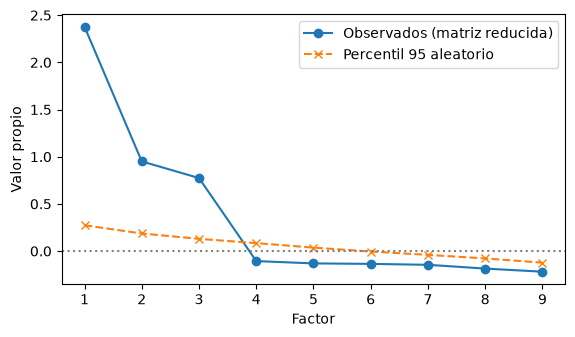

In [5]:
valores_propios = np.linalg.eigvalsh(R)[::-1]
print("Valores propios de R:", valores_propios.round(3))
print("Kaiser (λ > 1):", int((valores_propios > 1).sum()), "factores")

# Análisis paralelo sobre la matriz reducida (comunalidades iniciales = correlación múltiple al cuadrado)
def valores_propios_reducidos(M):
    Rm = np.corrcoef(M, rowvar=False)
    smc = 1 - 1 / np.diag(np.linalg.inv(Rm))
    np.fill_diagonal(Rm, smc)
    return np.linalg.eigvalsh(Rm)[::-1]

obs = valores_propios_reducidos(items.values.astype(float))
rng = np.random.default_rng(2026)
sim = np.array([valores_propios_reducidos(rng.normal(size=items.shape)) for _ in range(500)])
p95 = np.percentile(sim, 95, axis=0)
print("Factores sugeridos por el análisis paralelo:", int(np.argmax(obs < p95)))

plt.figure(figsize=(6.5, 3.5))
plt.plot(range(1, 10), obs, marker="o", label="Observados (matriz reducida)")
plt.plot(range(1, 10), p95, ls="--", marker="x", label="Percentil 95 aleatorio")
plt.axhline(0, ls=":", color="gray"); plt.xlabel("Factor"); plt.ylabel("Valor propio"); plt.legend()
plt.show()

**¿Qué observar?** Kaiser, el codo y el análisis paralelo coinciden en **tres factores**. En R, `psych::fa.parallel(fa = "fa")` reporta valores algo distintos porque estima las comunalidades de otra forma, pero llega a la misma conclusión.

## 3. Extracción y rotación oblicua (oblimin)

In [6]:
afe = FactorAnalyzer(n_factors=3, method="minres", rotation="oblimin").fit(items)
L, Phi = afe.loadings_, afe.phi_
patrones = pd.DataFrame(L, index=items.columns, columns=["F1", "F2", "F3"])
h2 = np.diag(L @ Phi @ L.T)              # comunalidad con factores correlacionados
patrones["h2"] = h2
patrones.round(3)

,F1,F2,F3,h2
inst_limpieza,-0.028,0.009,0.760,0.566
inst_comodidad,-0.022,-0.022,0.691,0.459
inst_equipos,0.098,0.020,0.643,0.476
trato_amabilidad,0.735,-0.013,-0.013,0.528
trato_escucha,0.739,0.007,0.004,0.551
trato_explicacion,0.682,0.015,0.034,0.489
opor_cita,0.024,0.693,0.016,0.498
opor_espera,-0.064,0.772,0.030,0.581
opor_tramites,0.090,0.637,-0.065,0.429


In [7]:
print("Correlaciones entre factores (Phi):")
print(pd.DataFrame(Phi, index=["F1", "F2", "F3"], columns=["F1", "F2", "F3"]).round(2))
estructura = pd.DataFrame(L @ Phi, index=items.columns, columns=["F1", "F2", "F3"])
print("\nMatriz de estructura (correlación ítem-factor):")
print(estructura.round(2))

Correlaciones entre factores (Phi):
      F1    F2    F3
F1  1.00  0.31  0.36
F2  0.31  1.00  0.26
F3  0.36  0.26  1.00

Matriz de estructura (correlación ítem-factor):
                     F1    F2    F3
inst_limpieza      0.25  0.20  0.75
inst_comodidad     0.22  0.15  0.68
inst_equipos       0.34  0.22  0.68
trato_amabilidad   0.73  0.21  0.25
trato_escucha      0.74  0.24  0.27
trato_explicacion  0.70  0.24  0.28
opor_cita          0.25  0.70  0.20
opor_espera        0.19  0.76  0.20
opor_tramites      0.27  0.65  0.13


**¿Qué observar?**
- **Matriz de patrones:** cada ítem carga entre 0,64 y 0,77 en un solo factor y menos de 0,10 en los demás: estructura simple. F1 = *Trato humano*, F2 = *Oportunidad*, F3 = *Infraestructura*.
- **Comunalidades** entre 0,43 y 0,58. Con rotación oblicua se calculan como la diagonal de $\Lambda\Phi\Lambda^{\top}$, no como la suma de cargas al cuadrado.
- **Matriz de estructura:** las correlaciones con los otros factores (0,13 a 0,34) aparecen porque los factores están correlacionados (Φ entre 0,26 y 0,36), no porque el ítem pertenezca a dos factores.

## 4. Comparación con una rotación ortogonal (varimax)

In [8]:
afe_v = FactorAnalyzer(n_factors=3, method="minres", rotation="varimax").fit(items)
comp = pd.DataFrame(afe_v.loadings_, index=items.columns, columns=["F1v", "F2v", "F3v"])
comp["h2_varimax"] = afe_v.get_communalities()
comp["h2_oblimin"] = h2
comp.round(3)

,F1v,F2v,F3v,h2_varimax,h2_oblimin
inst_limpieza,0.106,0.090,0.739,0.566,0.566
inst_comodidad,0.095,0.054,0.669,0.459,0.459
inst_equipos,0.209,0.108,0.649,0.476,0.476
trato_amabilidad,0.710,0.102,0.118,0.528,0.528
trato_escucha,0.719,0.125,0.137,0.551,0.551
trato_explicacion,0.670,0.126,0.157,0.489,0.489
opor_cita,0.122,0.687,0.106,0.498,0.498
opor_espera,0.050,0.752,0.113,0.581,0.581
opor_tramites,0.164,0.633,0.032,0.429,0.429


**¿Qué observar?** Con varimax los mismos ítems definen los mismos factores y las **comunalidades no cambian**: la rotación reorganiza la varianza común entre factores, pero no la modifica. Se prefiere oblimin porque es plausible que las dimensiones de percepción estén relacionadas, y Φ lo confirma.

> **Ítems Likert:** aquí se usan correlaciones de Pearson. Como análisis de sensibilidad, el script `R/02b_afe.R` repite el AFE con correlaciones policóricas (`psych::fa(cor = "poly")`): la estructura es la misma y las cargas suben a 0,66–0,81.

### ✍️ Tu turno

Ajusta el AFE con **dos factores** (oblimin) y compara con la solución de tres. ¿Qué ítems se agrupan? ¿Qué pasa con las comunalidades?

*Pista:* cambia `n_factors=3` por `n_factors=2` y calcula de nuevo h² con Φ.

<details>
<summary><b>Ver una solución posible</b></summary>

```python
afe2 = FactorAnalyzer(n_factors=2, method="minres", rotation="oblimin").fit(items)
L2, P2 = afe2.loadings_, afe2.phi_
pd.DataFrame(L2, index=items.columns).round(2), np.diag(L2 @ P2 @ L2.T).round(2)
```

Con dos factores, el factor 1 agrupa inst_limpieza, inst_comodidad, inst_equipos, trato_amabilidad, trato_escucha, trato_explicacion y el factor 2 agrupa opor_cita, opor_espera, opor_tramites. Al fusionarse trato humano e infraestructura en un solo factor, las comunalidades más bajas quedan en esos ítems (trato_amabilidad: 0,29; inst_comodidad: 0,30; trato_explicacion: 0,32). La solución mezcla dimensiones que el análisis paralelo distinguía, y es más difícil de interpretar: por eso se prefiere la de tres factores.

</details>

---
### Conecta con tu proyecto

Repite este flujo con la base de tu equipo. Guarda el cuaderno con salidas y verifica que se ejecute de principio a fin (*Entorno de ejecución → Reiniciar y ejecutar todo*) antes de entregarlo.

**Siguiente cuaderno:** `03a_conglomerados_jerarquicos_y_kmeans.ipynb`